# **Import and Load**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sellers = pd.read_csv('../data/cleaned/clean_sellers.csv')
deliveries = pd.read_csv('../data/cleaned/clean_deliveries.csv')
customer_service_tickets = pd.read_csv('../data/cleaned/clean_customer_service_tickets.csv')
transactions = pd.read_csv('../data/cleaned/clean_transactions.csv')
users = pd.read_csv('../data/cleaned/clean_users.csv')

# **Initialisasi Proporsi Repeat Order Rate yang Tepat**
Melakukan perhitungan untuk melihat persentase pelanggan yang kembali bertransaksi dalam jangka 90 hari dan pelanggan yang tidak.

Pendekatan yang dipilih adalah pendekatan yang menghasilkan persentase terendah.

## **1. Persentase ROR berdasarkan rata-rata interval transaksi**

In [3]:
# 1. Load data dan pastikan format tanggal sudah benar
transactions['order_date'] = pd.to_datetime(transactions['order_date'])

# 2. Filter HANYA transaksi yang menggunakan promo (promo_amount > 0)
promo_transactions = transactions[transactions['promo_amount'] > 0].copy()

# 3. Urutkan berdasarkan user_id dan tanggal untuk perhitungan interval yang benar
promo_transactions = promo_transactions.sort_values(by=['user_id', 'order_date'])

# 4. Hitung interval hari antar pesanan HANYA untuk transaksi berpromo
promo_transactions['days_since_last_promo_order'] = promo_transactions.groupby('user_id')['order_date'].diff().dt.days

# 5. Hitung rata-rata interval per user (seperti pendekatan Approach 1)
avg_promo_intervals = promo_transactions.groupby('user_id')['days_since_last_promo_order'].mean()

# 6. Hitung persentase ROR
total_promo_users = promo_transactions['user_id'].nunique()
promo_users_under_90_days = (avg_promo_intervals <= 90).sum()

pct_promo_repeats = (promo_users_under_90_days / total_promo_users) * 100

print(f"Total Pengguna Transaksi Promo Unik: {total_promo_users}")
print(f"Pengguna Promo dengan Rata-rata Interval <= 90 hari: {promo_users_under_90_days}")
print(f"Persentase Repeat Order (Promo): {pct_promo_repeats:.2f}%")

Total Pengguna Transaksi Promo Unik: 45998
Pengguna Promo dengan Rata-rata Interval <= 90 hari: 31422
Persentase Repeat Order (Promo): 68.31%


## **2. Persentase ROR berdasarkan dua transaksi pertama**

*Penjelasan*:
1. Bagi dataframe menjadi dua: Pelanggan yang bertransaksi SATU kali, dan pelanggan yang bertransaksi lebih dari satu.
2. Di grup >1 transaksi, HANYA hitung interval dari transaksi pertama dan kedua.
3. Cari persentase pelanggan yang bertransaksi kedua kalinya dalam rentang 90 hari dibanding dengan pengguna yang bertransaksi kedua melampaui batas tersebut.

In [4]:
# Load and prepare the data (using the logic from your notebook)
transactions['order_date'] = pd.to_datetime(transactions['order_date'])
transactions = transactions.sort_values(by=['user_id', 'order_date'])
transactions['days_since_last_order'] = transactions.groupby('user_id')['order_date'].diff().dt.days

# Create a column that numbers each transaction for a user chronologically
transactions['tx_number'] = transactions.groupby('user_id').cumcount() + 1

# --- STEP 1: Divide the dataframe ---
# Count total transactions per user and broadcast it back to the dataframe
tx_counts = transactions.groupby('user_id')['order_id'].transform('count')

# Isolate users who made more than one transaction
users_with_multi_tx = transactions[tx_counts > 1]

# --- STEP 2: Only calculate 1st vs 2nd transaction interval ---
# The 'days_since_last_order' on tx_number 2 represents the gap between order 1 and order 2
second_transactions = users_with_multi_tx[users_with_multi_tx['tx_number'] == 2]

# --- STEP 3: Find the percentage ---
# Compare users under the 90 day limit vs those who exceed it
under_90_days = (second_transactions['days_since_last_order'] <= 90).sum()
over_90_days = (second_transactions['days_since_last_order'] > 90).sum()
total_repeat_users = len(second_transactions)

# Calculate the final percentage
pct_under_90 = (under_90_days / total_repeat_users) * 100

print(f"Repeat Users (2nd order <= 90 days): {under_90_days}")
print(f"Repeat Users (2nd order > 90 days): {over_90_days}")
print(f"Percentage returning within 90 days: {pct_under_90:.2f}%")

Repeat Users (2nd order <= 90 days): 41560
Repeat Users (2nd order > 90 days): 208
Percentage returning within 90 days: 99.50%


## **3. Grafik Persentase ROR per bulan**

*Note: 3 bulan terakhir dieksklusikan karena ada pelanggan yang baru bertransaksi tidak memiliki rentang waktu yang cukup untuk mencapai batas 90 hari tersebut*

   cohort_month  total_users  successful_repeats  repeat_rate_pct
0       2023-01        23506               19028        80.949545
1       2023-02         1024                 759        74.121094
2       2023-03         1047                 814        77.745941
3       2023-04         1165                 878        75.364807
4       2023-05         1215                 948        78.024691
5       2023-06         1181                 941        79.678239
6       2023-07         1193                 947        79.379715
7       2023-08         1230                 972        79.024390
8       2023-09         1228                 970        78.990228
9       2023-10         1240                 967        77.983871
10      2023-11         1223                 986        80.621423
11      2023-12         1168                 909        77.825342
12      2024-01         1258                1027        81.637520
13      2024-02         1289                1027        79.674166
14      20

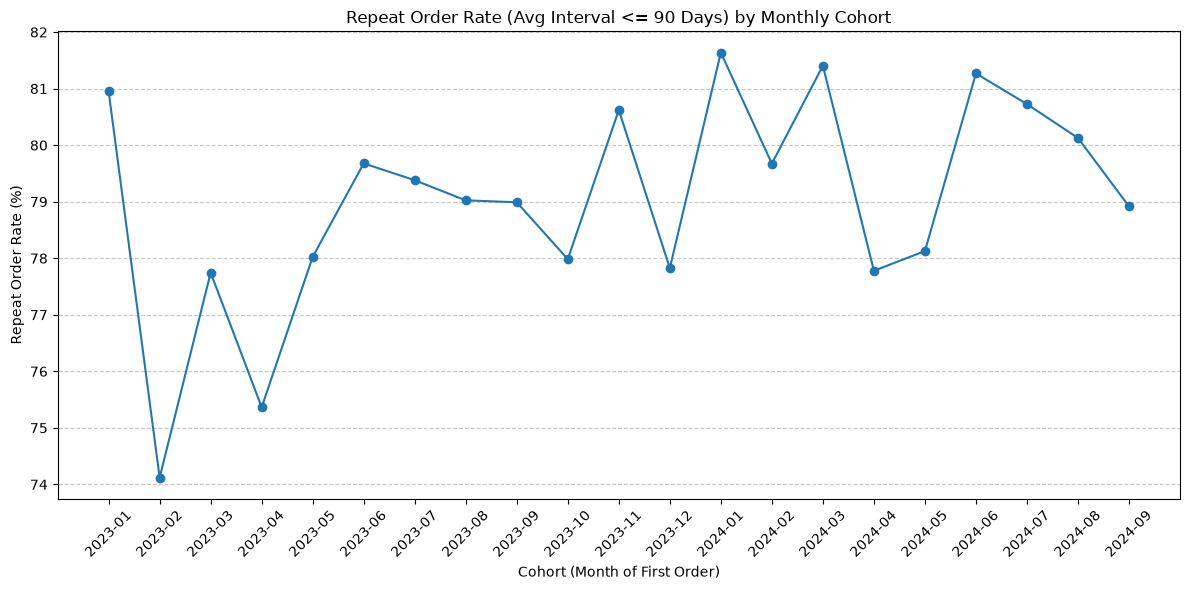

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Ensure order_date is datetime and sort the dataframe
transactions['order_date'] = pd.to_datetime(transactions['order_date'])
transactions = transactions.sort_values(by=['user_id', 'order_date'])

# 2. Calculate intervals between orders
transactions['days_since_last_order'] = transactions.groupby('user_id')['order_date'].diff().dt.days

# 3. Calculate each user's first order date AND their average interval
user_stats = transactions.groupby('user_id').agg(
    first_order_date=('order_date', 'min'),
    avg_interval=('days_since_last_order', 'mean')
).reset_index()

# 4. Extract the cohort month (e.g., "2023-01") from their first order date
user_stats['cohort_month'] = user_stats['first_order_date'].dt.to_period('M')

# 5. Determine if they meet the success criteria (<= 90 days)
user_stats['is_repeat_under_90'] = user_stats['avg_interval'] <= 90

# 6. Group by cohort to calculate the final percentages
cohort_metrics = user_stats.groupby('cohort_month').agg(
    total_users=('user_id', 'count'),
    successful_repeats=('is_repeat_under_90', 'sum')
).reset_index()

cohort_metrics['repeat_rate_pct'] = (cohort_metrics['successful_repeats'] / cohort_metrics['total_users']) * 100

# --- EXCLUDE THE LAST 3 MONTHS ---
# Find the latest cohort month in the dataset
latest_cohort = cohort_metrics['cohort_month'].max()

# Subtract 3 months to set the cutoff threshold
cutoff_cohort = latest_cohort - 3

# Filter the dataframe to only include cohorts up to the cutoff
filtered_cohorts = cohort_metrics[cohort_metrics['cohort_month'] <= cutoff_cohort]

print(filtered_cohorts)

# 7. Visualize the trend
plt.figure(figsize=(12, 6))
plt.plot(filtered_cohorts['cohort_month'].astype(str), filtered_cohorts['repeat_rate_pct'], marker='o', color='#1f77b4')
plt.title('Repeat Order Rate (Avg Interval <= 90 Days) by Monthly Cohort')
plt.xlabel('Cohort (Month of First Order)')
plt.ylabel('Repeat Order Rate (%)')
plt.xticks(rotation=45)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## **4. Persentase ROR untuk pelanggan promo**


In [6]:
# 1. Load data dan pastikan format tanggal sudah benar
transactions['order_date'] = pd.to_datetime(transactions['order_date'])

# 2. Filter HANYA transaksi yang menggunakan promo (promo_amount > 0)
promo_transactions = transactions[transactions['promo_amount'] > 0].copy()

# 3. Urutkan berdasarkan user_id dan tanggal untuk perhitungan interval yang benar
promo_transactions = promo_transactions.sort_values(by=['user_id', 'order_date'])

# 4. Hitung interval hari antar pesanan HANYA untuk transaksi berpromo
promo_transactions['days_since_last_promo_order'] = promo_transactions.groupby('user_id')['order_date'].diff().dt.days

# 5. Hitung rata-rata interval per user (seperti pendekatan Approach 1)
avg_promo_intervals = promo_transactions.groupby('user_id')['days_since_last_promo_order'].mean()

# 6. Hitung persentase ROR
total_promo_users = promo_transactions['user_id'].nunique()
promo_users_under_90_days = (avg_promo_intervals <= 90).sum()

pct_promo_repeats = (promo_users_under_90_days / total_promo_users) * 100

print(f"Total Pengguna Transaksi Promo Unik: {total_promo_users}")
print(f"Pengguna Promo dengan Rata-rata Interval <= 90 hari: {promo_users_under_90_days}")
print(f"Persentase Repeat Order (Promo): {pct_promo_repeats:.2f}%")

Total Pengguna Transaksi Promo Unik: 45998
Pengguna Promo dengan Rata-rata Interval <= 90 hari: 31422
Persentase Repeat Order (Promo): 68.31%


## **Kesimpulan**

> Karena persentase ROR untuk pelanggan promo menghasilkan angka yang terbaik, maka untuk tahap-tahap selanjutnya akan memakai pendekatan ini untuk mencari nilai ROR.

# **Exploratory Data Analysis**

**Tujuan Data Analisis (WAJIB DIBACA)**
- Meningkatkan persentase repeat order rate yang kali ini duduk di 68% ke persentase terbaik yang bisa dicapai.
- Memastikan alokasi promo mendorong nilai jangka panjang (CLV), bukan
sekadar transaksi sesaat yang tidak berkelanjutan.

In [7]:
# --- SETUP DATA LEVEL USER ---
# Gabungkan transaksi dengan data user untuk mendapatkan acquisition_channel, age, dll
df_merged = transactions.merge(users, on='user_id', how='left')

# Definisikan retensi (Repeat Order Rate <= 90 hari) berdasarkan pendekatan Anda sebelumnya
df_merged['order_date'] = pd.to_datetime(df_merged['order_date'])
df_merged = df_merged.sort_values(by=['user_id', 'order_date'])
df_merged['days_since_last_order'] = df_merged.groupby('user_id')['order_date'].diff().dt.days

# Agregasi ke level user
user_profile = df_merged.groupby('user_id').agg(
    first_order_date=('order_date', 'min'),
    total_transactions=('order_id', 'nunique'),
    total_gmv=('total_amount', 'sum'),
    total_promo_absorbed=('promo_amount', 'sum'),
    avg_interval=('days_since_last_order', 'mean'),
    acquisition_channel=('acquisition_channel', 'first'),
    age=('age', 'first'),
    device_type=('device_type', 'first'),
    account_status=('account_status', 'first')
).reset_index()

# Tentukan label Retained vs Churned (Acuan sehat: Repeat order <= 90 hari)
user_profile['is_retained'] = ((user_profile['total_transactions'] > 1) & (user_profile['avg_interval'] <= 90)).astype(int)

# Hitung rasio promo terhadap total transaksi (seberapa besar user ini bergantung pada promo)
user_profile['promo_reliance_ratio'] = user_profile['total_promo_absorbed'] / user_profile['total_gmv']
user_profile['promo_reliance_ratio'] = user_profile['promo_reliance_ratio'].fillna(0)

user_profile.head()

,user_id,first_order_date,total_transactions,total_gmv,total_promo_absorbed,avg_interval,acquisition_channel,age,device_type,account_status,is_retained,promo_reliance_ratio
0,222FPT2RQE,2024-12-25,1,2106904.0,12605,NaN,ads,35.0,Android,active,0,0.005983
1,222TKKG47G,2023-11-12,2,1050545.0,56418,13.000000,organic,46.0,Android,active,1,0.053704
2,2242MWUZJL,2023-10-14,7,2965323.0,46542,12.000000,affiliate,41.0,Android,active,1,0.015695
3,224DPQ8JV4,2023-01-02,1,179192.0,0,NaN,NaN,NaN,NaN,NaN,0,0.000000
4,224JW2JMEQ,2024-10-09,7,4949449.0,74613,10.666667,referral,65.0,Android,active,1,0.015075


## **1. Efektivitas dan Biaya Promo untuk Setiap Segmen Kanal Akuisisi**

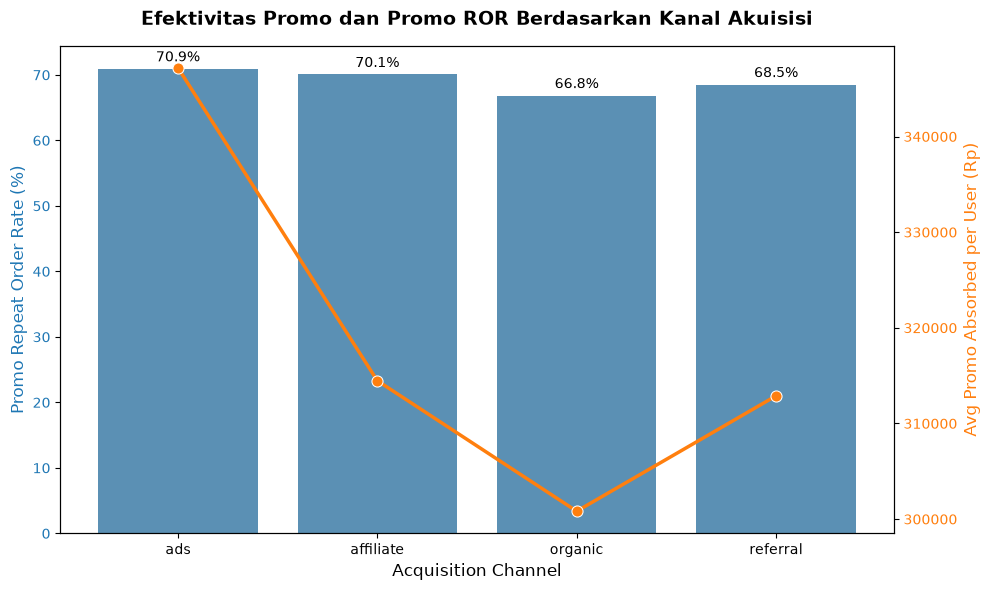

  acquisition_channel  promo_ror_percentage  avg_promo_per_user  clv_cac_proxy
0                 ads             70.924262       347187.295393      22.468905
1           affiliate             70.059484       314468.389293      24.562441
3            referral             68.518249       312886.749600      24.065572
2             organic             66.838868       300822.440886      22.388481


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 2. EFEKTIVITAS PROMO ANTAR SEGMEN KANAL AKUISISI (BASED ON PROMO ROR) ---

# 1. Filter HANYA transaksi yang menggunakan promo
promo_tx = df_merged[df_merged['promo_amount'] > 0].copy()

# 2. Urutkan dan hitung interval hari HANYA antar pesanan berpromo
promo_tx = promo_tx.sort_values(by=['user_id', 'order_date'])
promo_tx['days_since_last_promo_order'] = promo_tx.groupby('user_id')['order_date'].diff().dt.days

# 3. Agregasi metrik ke level User
promo_user_profile = promo_tx.groupby('user_id').agg(
    avg_promo_interval=('days_since_last_promo_order', 'mean'),
    total_promo_absorbed=('promo_amount', 'sum'),
    total_gmv_from_promo=('total_amount', 'sum'),
    acquisition_channel=('acquisition_channel', 'first')
).reset_index()

# 4. Tentukan status Retensi Promo (Rata-rata interval promo <= 90 hari)
# Nilai NaN (user yang hanya memakai promo 1 kali) otomatis menjadi False/0
promo_user_profile['is_promo_retained'] = (promo_user_profile['avg_promo_interval'] <= 90).astype(int)

# 5. Agregasi metrik efektivitas ke level Kanal Akuisisi
channel_effectiveness = promo_user_profile.groupby('acquisition_channel').agg(
    total_promo_users=('user_id', 'count'),
    retained_promo_users=('is_promo_retained', 'sum'),
    avg_promo_per_user=('total_promo_absorbed', 'mean'),
    avg_gmv_per_user=('total_gmv_from_promo', 'mean')
).reset_index()

# Hitung Persentase Promo ROR dan Rasio Proksi CLV:CAC
channel_effectiveness['promo_ror_percentage'] = (channel_effectiveness['retained_promo_users'] / channel_effectiveness['total_promo_users']) * 100
channel_effectiveness['clv_cac_proxy'] = channel_effectiveness['avg_gmv_per_user'] / channel_effectiveness['avg_promo_per_user']

# --- VISUALISASI DUAL-AXIS ---
fig, ax1 = plt.subplots(figsize=(10, 6))

# Axis 1: Promo Repeat Order Rate (Bar Chart)
sns.barplot(
    data=channel_effectiveness,
    x='acquisition_channel',
    y='promo_ror_percentage',
    color='#1f77b4',
    ax=ax1,
    alpha=0.8
)
ax1.set_ylabel('Promo Repeat Order Rate (%)', color='#1f77b4', fontsize=12)
ax1.set_xlabel('Acquisition Channel', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#1f77b4')

# Menambahkan label persentase di atas bar
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

# Axis 2: Rata-rata Promo yang Diserap (Line Chart)
ax2 = ax1.twinx()
sns.lineplot(
    data=channel_effectiveness,
    x='acquisition_channel',
    y='avg_promo_per_user',
    color='#ff7f0e',
    marker='o',
    linewidth=2.5,
    markersize=8,
    ax=ax2
)
ax2.set_ylabel('Avg Promo Absorbed per User (Rp)', color='#ff7f0e', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#ff7f0e')

# Format Judul dan Layout
plt.title('Efektivitas Promo dan Promo ROR Berdasarkan Kanal Akuisisi', fontsize=14, pad=15, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

# Menampilkan tabel hasil ringkasan
print(channel_effectiveness[['acquisition_channel', 'promo_ror_percentage', 'avg_promo_per_user', 'clv_cac_proxy']].sort_values('promo_ror_percentage', ascending=False))

### **Insight**

**Key Findings**

- Persentase promo repeat order rate (ROR) cenderung merata antar kanal.
- Biaya promo rata-rata yang diserap per pelanggan berkontras tiap kanal.
- Kanal Ads menyerap biaya rata-rata promo per pengguna paling tinggi, tetapi menghasilkan rasio proksi CLV:CAC paling rendah
- Kanal Referral dan Organic mampu menghasilkan nilai transaksi jangka panjang yang jauh lebih efisien dengan biaya subsidi yang lebih hemat.

**Langkah Selanjutnya**

Karena kanal akuisisi sendiri belum bisa memisahkan pelanggan yang loyal dan yang churn, langkah yang bisa diambil berikutnya adalah mencari persentase serapan biaya promo terhadap metrik segmen-segmen lainnya.

## **2. Efektivitas dan Biaya Promo untuk Setiap Segmen Lainnya**

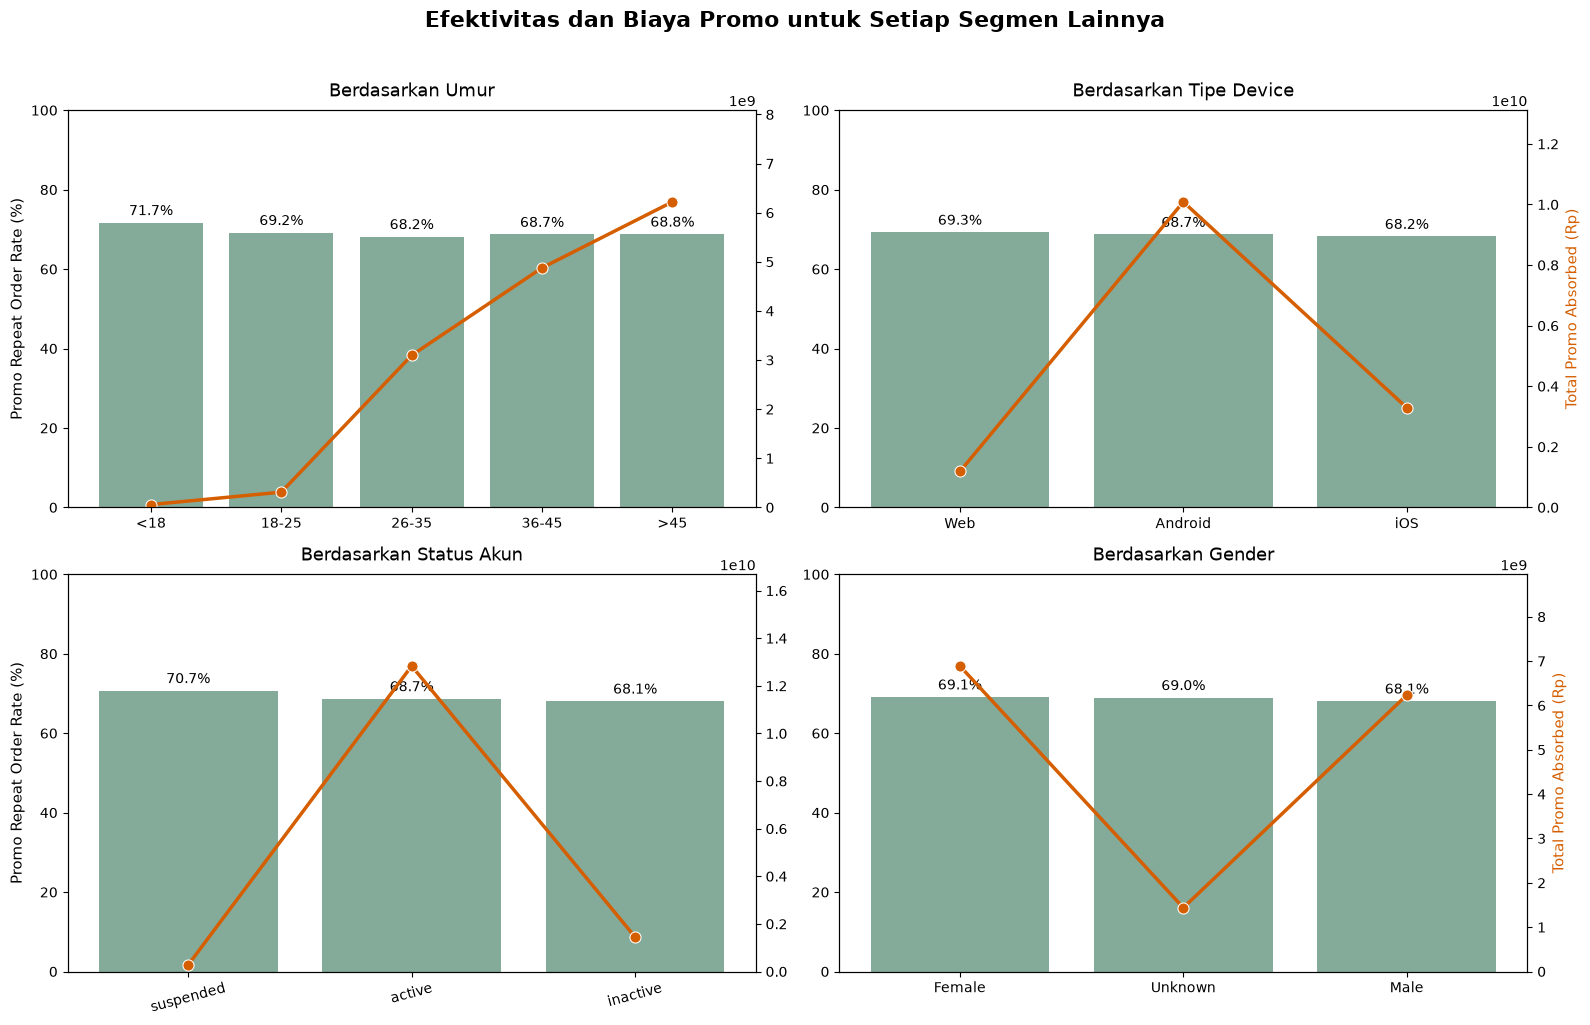

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- 1. PERSIAPAN DATA PROMO ROR LEVEL USER ---

# Pastikan format tanggal sudah benar (menggunakan df_merged atau transactions)
df_merged['order_date'] = pd.to_datetime(df_merged['order_date'])

# Filter HANYA transaksi yang menggunakan promo
promo_transactions = df_merged[df_merged['promo_amount'] > 0].copy()

# Urutkan dan hitung interval hari antar pesanan berpromo
promo_transactions = promo_transactions.sort_values(by=['user_id', 'order_date'])
promo_transactions['days_since_last_promo_order'] = promo_transactions.groupby('user_id')['order_date'].diff().dt.days

# Agregasi untuk mendapatkan rata-rata interval promo dan total promo per user
promo_user_profile = promo_transactions.groupby('user_id').agg(
    avg_promo_interval=('days_since_last_promo_order', 'mean'),
    total_promo_absorbed=('promo_amount', 'sum')
).reset_index()

# Hitung Persentase ROR Promo (<= 90 hari)
promo_user_profile['is_promo_retained'] = (promo_user_profile['avg_promo_interval'] <= 90).astype(int)

# Gabungkan dengan tabel users untuk mendapatkan kolom dimensi (age, device_type, account status, gender)
promo_user_profile = promo_user_profile.merge(users, on='user_id', how='left')

# Standardisasi nama kolom jika dataset menggunakan spasi pada 'account status'
if 'account status' in promo_user_profile.columns:
    promo_user_profile = promo_user_profile.rename(columns={'account status': 'account_status'})


# --- 2. EFEKTIVITAS DAN BIAYA PROMO UNTUK SETIAP SEGMEN LAINNYA ---

# Pastikan data umur di-binning
bins = [0, 18, 25, 35, 45, 100]
labels = ['<18', '18-25', '26-35', '36-45', '>45']
if 'age_group' not in promo_user_profile.columns:
    promo_user_profile['age_group'] = pd.cut(promo_user_profile['age'], bins=bins, labels=labels)

# Menyiapkan segmen yang akan dianalisis
segments = ['age_group', 'device_type', 'account_status', 'gender']
titles = ['Berdasarkan Umur', 'Berdasarkan Tipe Device', 'Berdasarkan Status Akun', 'Berdasarkan Gender']

# Siapkan Figure dengan 4 Subplot (Grid 2x2)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten() # Ratakan array axes untuk memudahkan iterasi

for i, col in enumerate(segments):
    # Agregasi data untuk masing-masing segmen (menggunakan is_promo_retained)
    seg_data = promo_user_profile.groupby(col, observed=True).agg(
        total_users=('user_id', 'count'),
        ror_percentage=('is_promo_retained', lambda x: x.mean() * 100),
        total_promo_absorbed=('total_promo_absorbed', 'sum')
    ).dropna().reset_index()

    # Filter kelompok user yang jumlahnya memadai
    seg_data = seg_data[seg_data['total_users'] > 10]

    # Urutkan data berdasarkan ROR menurun (Kecuali umur agar tetap urut secara logis)
    if col != 'age_group':
        seg_data = seg_data.sort_values('ror_percentage', ascending=False)

    # Axis 1: Bar Chart untuk ROR (%)
    sns.barplot(
        data=seg_data,
        x=col,
        y='ror_percentage',
        color='#7EB09B', # Warna Bar (Soft Green)
        ax=axes[i]
    )

    # Menambahkan label persentase di atas setiap Bar
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

    # Axis 2: Line Chart untuk Total Promo Absorbed (Sumbu Y Sekunder)
    ax2 = axes[i].twinx()
    sns.lineplot(
        data=seg_data,
        x=col,
        y='total_promo_absorbed',
        color='#D55E00', # Warna Line (Orange-Red)
        marker='o',
        linewidth=2.5,
        markersize=8,
        ax=ax2
    )

    # Format judul dan rotasi label X
    axes[i].set_title(titles[i], fontsize=13, pad=10)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=15 if col == 'account_status' else 0)

    # Mengatur dan merapikan Label Sumbu Y
    # Sumbu Y Utama (Kiri) - ROR %
    if i % 2 == 0: # Hanya tampilkan label Y untuk kolom paling kiri
        axes[i].set_ylabel('Promo Repeat Order Rate (%)', fontsize=11)
    else:
        axes[i].set_ylabel('')

    # Sumbu Y Sekunder (Kanan) - Total Promo
    if i % 2 != 0: # Hanya tampilkan label Y sekunder untuk kolom paling kanan
        ax2.set_ylabel('Total Promo Absorbed (Rp)', fontsize=11, color='#D55E00')
    else:
        ax2.set_ylabel('')

    # Menyesuaikan batas atas (Limit) agar grafik lebih estetik dan tidak terpotong
    axes[i].set_ylim(0, max(seg_data['ror_percentage'].max() + 20, 100)) # Skala ROR min 100% atau +20% ruang ekstra
    ax2.set_ylim(0, seg_data['total_promo_absorbed'].max() * 1.3) # Ruang ekstra 30% di atas garis promo

# Mengubah Judul Utama sesuai arahan
plt.suptitle('Efektivitas dan Biaya Promo untuk Setiap Segmen Lainnya', fontsize=16, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

### **Insight**

*Note: Mengingat bahwa variabel gender kurang etis jika menjadi metrik analisis, maka untuk grafik gender tidak akan dianalisis maupun ditindaklanjuti.*

**Key Findings**

- Dari keempat segmen, persentase ROR sangat stabil di kisaran 68% - 71%.
- Penyerapan promo terkonsentrasi pada pengguna yang berusia di atas 45 tahun serta pengguna perangkat Android.

**Langkah Selanjutnya**

Karena atribut demografi tidak terlalu menonjolkan temuan yang signifikan untuk bisa dilanjutkan, langkah yang bisa diambil berikutnya adalah menganalisis pola penggunaan promo, seperti jenis voucher yang dipakai, transaksi di periode kampanye, hingga tingkat intensitas diskon, agar bisa melihat dampaknya terhadap CLV dan retensi.


## **3. Analisis Pola Penggunaan Promo (Jenis Voucher, Periode Kampanye, dan Kategori Produk)**

Melihat bagaimana perilaku pelanggan saat menggunakan promo pada transaksi pertama mereka (berdasarkan jenis voucher, periode kampanye/flash sale, dan kategori produk) memengaruhi tingkat retensi (Promo ROR) serta efisiensi nilai jangka panjang (rasio GMV terhadap Promo).

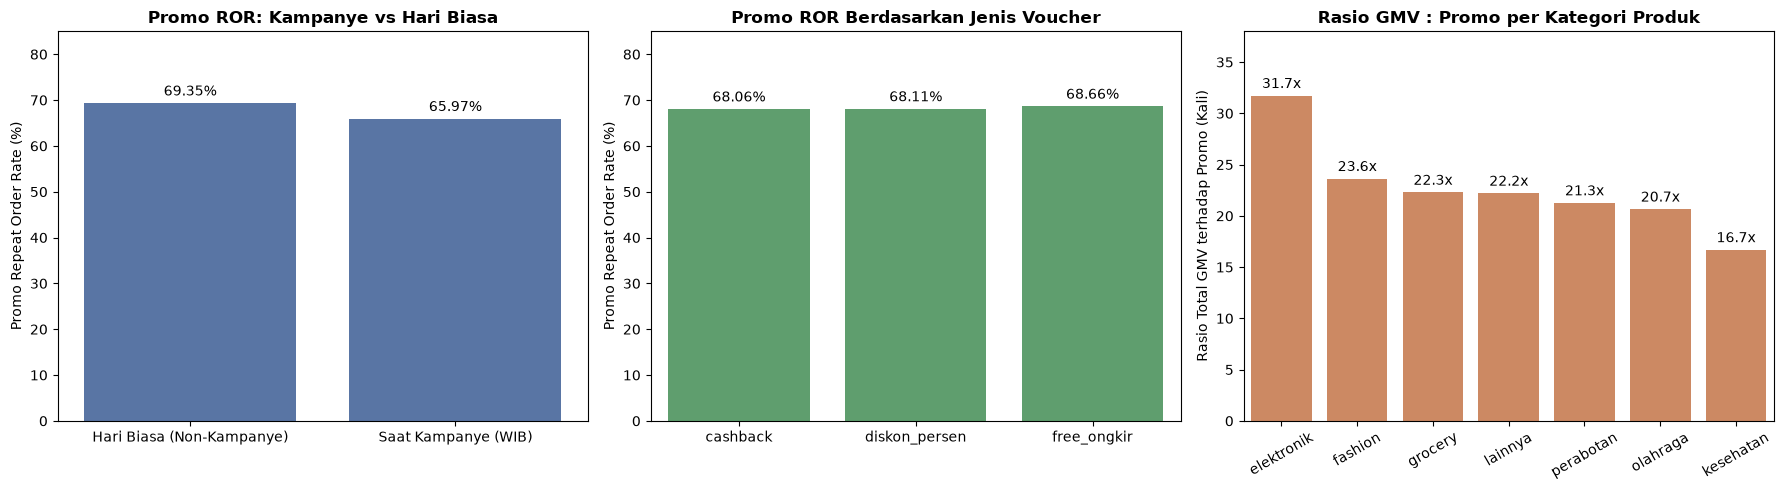

In [10]:
# --- 3. POLA PENGGUNAAN PROMO: JENIS VOUCHER, KAMPANYE, DAN KATEGORI ---

# 1. Urutkan transaksi promo secara kronologis per user
promo_tx = df_merged[df_merged['promo_amount'] > 0].copy()
promo_tx['order_date'] = pd.to_datetime(promo_tx['order_date'])
promo_tx = promo_tx.sort_values(by=['user_id', 'order_date'])
promo_tx['days_since_last_promo_order'] = promo_tx.groupby('user_id')['order_date'].diff().dt.days

# 2. Ambil karakteristik transaksi promo pertama setiap user beserta total GMV dan Promo selama mereka bertransaksi
user_promo_pattern = promo_tx.groupby('user_id').agg(
    avg_promo_interval=('days_since_last_promo_order', 'mean'),
    total_promo_absorbed=('promo_amount', 'sum'),
    total_gmv=('total_amount', 'sum'),
    first_voucher_type=('voucher_type', 'first'),
    first_is_campaign=('is_campaign_period', 'first'),
    first_product_category=('product_category', 'first')
).reset_index()

user_promo_pattern['is_promo_retained'] = (user_promo_pattern['avg_promo_interval'] <= 90).astype(int)
user_promo_pattern['campaign_label'] = user_promo_pattern['first_is_campaign'].map({1: 'Saat Kampanye (WIB)', 0: 'Hari Biasa (Non-Kampanye)'})

# 3. Siapkan ringkasan data untuk 3 dimensi pola promo
voucher_summary = user_promo_pattern.groupby('first_voucher_type').agg(
    ror_pct=('is_promo_retained', lambda x: x.mean() * 100),
    clv_cac_proxy=('total_gmv', lambda x: x.sum() / user_promo_pattern.loc[x.index, 'total_promo_absorbed'].sum())
).reset_index()

campaign_summary = user_promo_pattern.groupby('campaign_label').agg(
    ror_pct=('is_promo_retained', lambda x: x.mean() * 100),
    clv_cac_proxy=('total_gmv', lambda x: x.sum() / user_promo_pattern.loc[x.index, 'total_promo_absorbed'].sum())
).reset_index()

category_summary = user_promo_pattern.groupby('first_product_category').agg(
    ror_pct=('is_promo_retained', lambda x: x.mean() * 100),
    clv_cac_proxy=('total_gmv', lambda x: x.sum() / user_promo_pattern.loc[x.index, 'total_promo_absorbed'].sum())
).sort_values(by='clv_cac_proxy', ascending=False).reset_index()

# --- VISUALISASI SEDERHANA (1x3 SUBPLOTS) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: ROR berdasarkan Periode Kampanye
sns.barplot(data=campaign_summary, x='campaign_label', y='ror_pct', color='#4C72B0', ax=axes[0])
axes[0].set_title('Promo ROR: Kampanye vs Hari Biasa', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Promo Repeat Order Rate (%)')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 85)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f%%', padding=3)

# Plot 2: ROR berdasarkan Jenis Voucher
sns.barplot(data=voucher_summary, x='first_voucher_type', y='ror_pct', color='#55A868', ax=axes[1])
axes[1].set_title('Promo ROR Berdasarkan Jenis Voucher', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Promo Repeat Order Rate (%)')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 85)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f%%', padding=3)

# Plot 3: Rasio Efisiensi CLV (GMV/Promo) per Kategori Produk
sns.barplot(data=category_summary, x='first_product_category', y='clv_cac_proxy', color='#DD8452', ax=axes[2])
axes[2].set_title('Rasio GMV : Promo per Kategori Produk', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Rasio Total GMV terhadap Promo (Kali)')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=30)
axes[2].set_ylim(0, 38)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.1fx', padding=3)

plt.tight_layout()
plt.show()

### **Insight**

**Key Findings**

- Pelanggan yang menggunakan promo pertama kali saat periode kampanye besar (WIB) justru memiliki tingkat retensi (ROR) yang lebih rendah dibandingkan pelanggan yang bertransaksi di hari biasa, mengindikasikan bahwa kampanye besar cenderung menarik pencari diskon musiman (*discount seekers*) yang kurang loyal.
- Jenis voucher *Free Ongkir* mampu menghasilkan tingkat retensi paling tinggi dengan beban biaya subsidi per pelanggan yang paling hemat dibandingkan jenis promo lainnya.
- Meskipun tingkat ROR antar kategori produk cenderung merata, kategori Elektronik dan Fashion memberikan timbal balik nilai transaksi jangka panjang (rasio GMV terhadap Promo) paling tinggi, sedangkan kategori Kesehatan menjadi yang paling rendah.

**Langkah Selanjutnya**

Untuk memahami lebih dalam mengapa sebagian anggaran promo gagal menghasilkan efisiensi nilai jangka panjang (CLV) yang sehat, langkah yang bisa diambil berikutnya adalah mengaudit tingkat intensitas besaran diskon yang diberikan pada tiap transaksi guna melihat apakah terdapat ketidakwajaran alokasi subsidi (*over-subsidy*).

## **4. Analisis Efisiensi Alokasi Budget Promo & Anomali Subsidi Berlebih (Over-Subsidy)**
Mengevaluasi seberapa sehat alokasi nominal promo terhadap nilai belanja pelanggan (GMV), khususnya mengidentifikasi kebocoran anggaran pada transaksi dengan nominal promo ekstrem (>Rp50.000 atau melebihi nilai belanja).

                               kategori_subsidi  jumlah_transaksi  \
0        Promo > Total Belanja\n(Anomali Bocor)             11916   
1                     Promo Normal\n(<= Rp50rb)            139766   
2  Promo Sangat Besar\n(>Rp50rb - s.d Rp1 Juta)              4367   

   pct_transaksi  total_budget_promo  pct_budget_promo  roi_gmv_to_promo  
0       7.636063          8571306957         58.791279          0.380477  
1      89.565457          2842828743         19.499190        103.371949  
2       2.798480          3165079187         21.709531         11.499736  


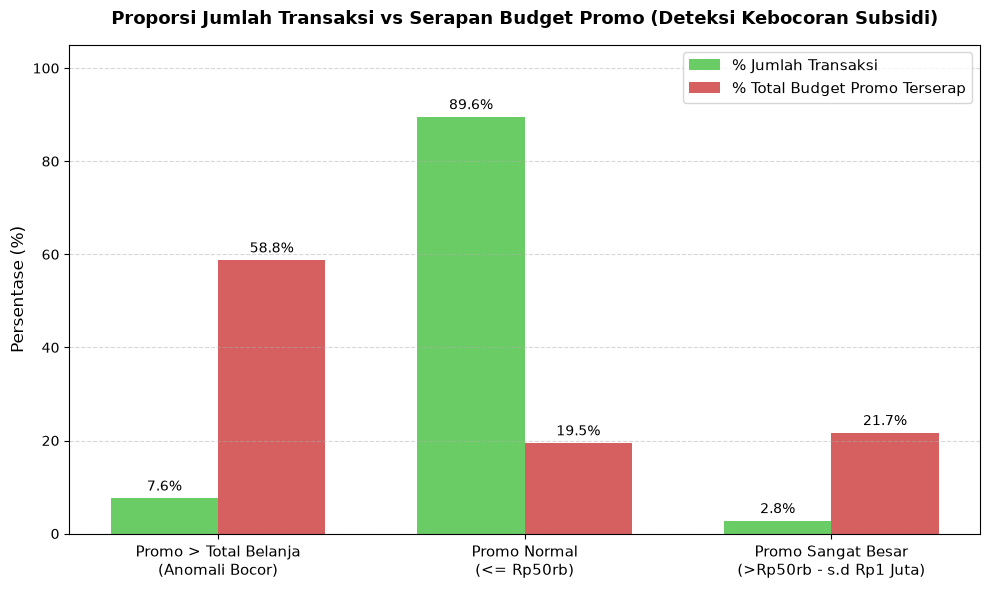

In [11]:
# --- 4. ANALISIS KEBOCORAN BUDGET PROMO (OVER-SUBSIDY vs NORMAL PROMO) ---

# Gunakan kolom penanda (flag) dari proses data cleaning untuk melihat efisiensi budget promo
promo_tx['kategori_subsidi'] = np.where(
    promo_tx['flag_promo_melebihi_total'] == True, 'Promo > Total Belanja\n(Anomali Bocor)',
    np.where(promo_tx['flag_promo_sangat_besar'] == True, 'Promo Sangat Besar\n(>Rp50rb - s.d Rp1 Juta)', 'Promo Normal\n(<= Rp50rb)')
)

subsidy_analysis = promo_tx.groupby('kategori_subsidi').agg(
    jumlah_transaksi=('order_id', 'count'),
    total_budget_promo=('promo_amount', 'sum'),
    total_gmv=('total_amount', 'sum')
).reset_index()

# Hitung persentase porsi transaksi vs porsi serapan budget promo
total_all_promo_tx = subsidy_analysis['jumlah_transaksi'].sum()
total_all_promo_budget = subsidy_analysis['total_budget_promo'].sum()

subsidy_analysis['pct_transaksi'] = (subsidy_analysis['jumlah_transaksi'] / total_all_promo_tx) * 100
subsidy_analysis['pct_budget_promo'] = (subsidy_analysis['total_budget_promo'] / total_all_promo_budget) * 100
subsidy_analysis['roi_gmv_to_promo'] = subsidy_analysis['total_gmv'] / subsidy_analysis['total_budget_promo']

print(subsidy_analysis[['kategori_subsidi', 'jumlah_transaksi', 'pct_transaksi', 'total_budget_promo', 'pct_budget_promo', 'roi_gmv_to_promo']])

# --- VISUALISASI PERBANDINGAN PORSI TRANSAKSI VS PORSI SERAPAN BUDGET PROMO ---
x = np.arange(len(subsidy_analysis['kategori_subsidi']))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, subsidy_analysis['pct_transaksi'], width, label='% Jumlah Transaksi', color='#6ACC64')
rects2 = ax.bar(x + width/2, subsidy_analysis['pct_budget_promo'], width, label='% Total Budget Promo Terserap', color='#D65F5F')

ax.set_ylabel('Persentase (%)', fontsize=12)
ax.set_title('Proporsi Jumlah Transaksi vs Serapan Budget Promo (Deteksi Kebocoran Subsidi)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(subsidy_analysis['kategori_subsidi'], fontsize=11)
ax.set_ylim(0, 105)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

ax.bar_label(rects1, fmt='%.1f%%', padding=3)
ax.bar_label(rects2, fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.show()

### **Insight**

**Key Findings**

- Mayoritas transaksi berpromo sebenarnya berada pada batas nominal promo yang wajar dan hanya menyerap porsi kecil dari total anggaran, namun mampu menghasilkan timbal balik nilai belanja (GMV) yang sangat sehat.
- Sebagian besar anggaran promo Tokopedia justru habis tersedot oleh segelintir transaksi yang memberikan nominal potongan promo sangat besar.
- Ditemukan kebocoran anggaran yang serius pada sejumlah transaksi anomali di mana nilai potongan promo melebihi total nilai belanja pelanggan, yang menjadi penyebab utama rusaknya rasio efisiensi *CLV:CAC* perusahaan.

**Langkah Selanjutnya**

Setelah menemukan sumber utama kebocoran anggaran promo yang menggerus profitabilitas, langkah selanjutnya adalah mencari faktor penentu di luar variabel promo—khususnya pengalaman operasional pasca-pembelian seperti pengiriman dan layanan komplain pada transaksi pertama—untuk mengetahui penyebab tertahannya *Repeat Order Rate* di angka 68%.

## **5. Faktor Penentu Retensi di Luar Promo: Pengalaman Pengiriman dan Komplain pada Transaksi Pertama**
Menguji hipotesis apakah kegagalan pengguna untuk kembali bertransaksi dalam 90 hari (ROR) disebabkan oleh buruknya pengalaman operasional (keterlambatan SLA pengiriman kurir, kegagalan pengiriman, dan munculnya tiket komplain CS) pada pesanan promo pertama mereka.

C:\Users\DELL\AppData\Local\Temp\ipykernel_18096\3775126110.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ticket_ror, x='status_komplain', y='ror_pct', palette=['#2CA02C', '#D62728'], ax=axes[0])
C:\Users\DELL\AppData\Local\Temp\ipykernel_18096\3775126110.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sla_ror, x='status_sla', y='ror_pct', palette=['#1F77B4', '#FF7F0E'], ax=axes[1])


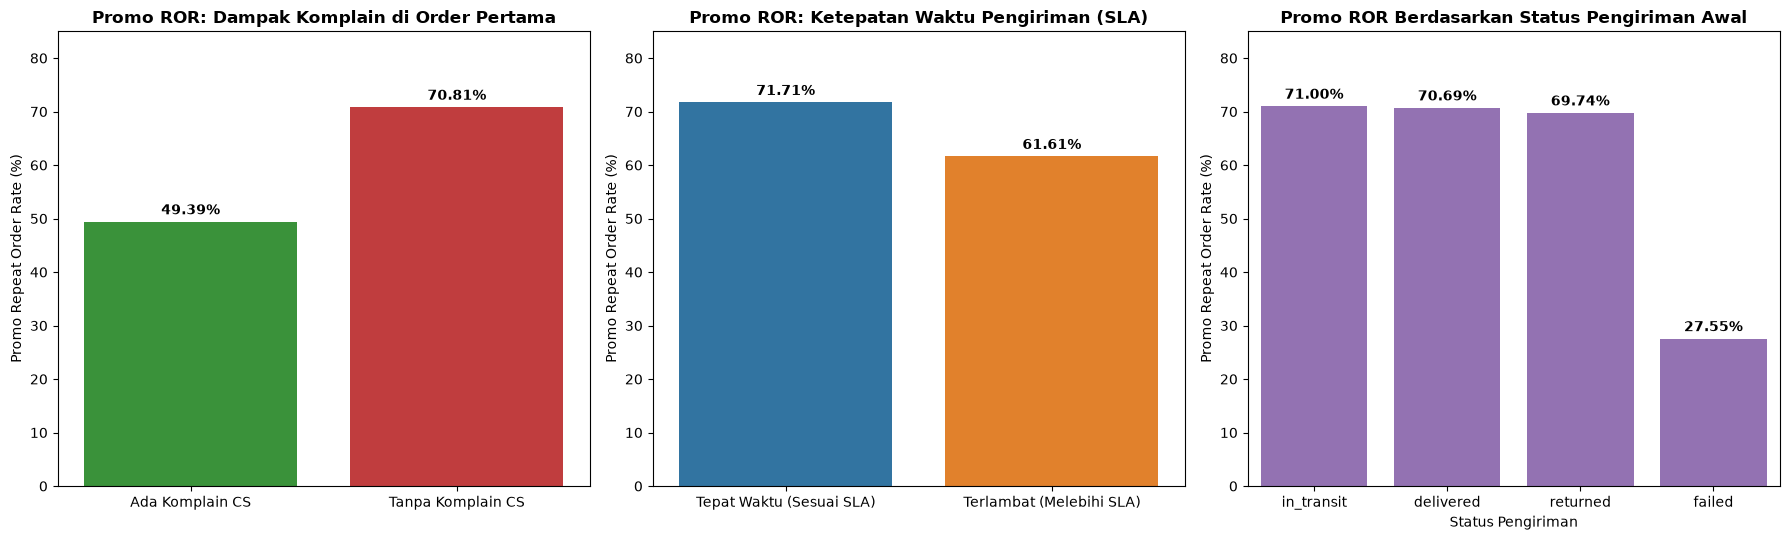

--- Detail Pengguna Berdasarkan Komplain Order Pertama ---
     status_komplain  total_users    ror_pct
0    Ada Komplain CS         5371  49.394899
1  Tanpa Komplain CS        40627  70.810052

--- Detail Pengguna Berdasarkan Ketepatan SLA Order Pertama ---
                 status_sla  total_users    ror_pct
0  Tepat Waktu (Sesuai SLA)        30518  71.705223
1  Terlambat (Melebihi SLA)        15480  61.614987

--- Detail Pengguna Berdasarkan Status Pengiriman Order Pertama ---
  first_delivery_status  total_users    ror_pct
0            in_transit          907  71.003308
1             delivered        41540  70.686086
2              returned         1213  69.744435
3                failed         2036  27.554028


In [12]:
# --- 5. DAMPAK PENGIRIMAN DAN KOMPLAIN TRANSAKSI PERTAMA TERHADAP PROMO ROR ---

# 1. Gabungkan data transaksi promo dengan data pengiriman (deliveries)
promo_with_ops = promo_tx.merge(
    deliveries[['order_id', 'delivery_status', 'sla_promised_days', 'dispatch_date', 'delivery_date', 'courier_rating']],
    on='order_id',
    how='left'
)

# Hitung keterlambatan pengiriman (SLA Breach: durasi kirim aktual > janji SLA)
promo_with_ops['dispatch_date'] = pd.to_datetime(promo_with_ops['dispatch_date'])
promo_with_ops['delivery_date'] = pd.to_datetime(promo_with_ops['delivery_date'])
promo_with_ops['actual_delivery_days'] = (promo_with_ops['delivery_date'] - promo_with_ops['dispatch_date']).dt.days
promo_with_ops['is_sla_breach'] = promo_with_ops['actual_delivery_days'] > promo_with_ops['sla_promised_days']

# 2. Ambil pengalaman pada transaksi promo PERTAMA setiap pelanggan
first_order_ops = promo_with_ops.groupby('user_id').agg(
    avg_promo_interval=('days_since_last_promo_order', 'mean'),
    first_has_ticket=('punya_tiket', 'first'),
    first_sla_breach=('is_sla_breach', 'first'),
    first_delivery_status=('delivery_status', 'first')
).reset_index()

first_order_ops['is_promo_retained'] = (first_order_ops['avg_promo_interval'] <= 90).astype(int)

# Label untuk visualisasi
first_order_ops['status_komplain'] = first_order_ops['first_has_ticket'].map({False: 'Tanpa Komplain CS', True: 'Ada Komplain CS'})
first_order_ops['status_sla'] = first_order_ops['first_sla_breach'].map({False: 'Tepat Waktu (Sesuai SLA)', True: 'Terlambat (Melebihi SLA)'})

# 3. Hitung ROR untuk masing-masing kondisi operasional
ticket_ror = first_order_ops.groupby('status_komplain')['is_promo_retained'].agg(
    total_users='count',
    ror_pct=lambda x: x.mean() * 100
).reset_index()

sla_ror = first_order_ops.groupby('status_sla')['is_promo_retained'].agg(
    total_users='count',
    ror_pct=lambda x: x.mean() * 100
).reset_index()

deliv_status_ror = first_order_ops.dropna(subset=['first_delivery_status']).groupby('first_delivery_status')['is_promo_retained'].agg(
    total_users='count',
    ror_pct=lambda x: x.mean() * 100
).sort_values(by='ror_pct', ascending=False).reset_index()

# --- VISUALISASI SEDERHANA (1x3 SUBPLOTS) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Plot 1: Dampak Komplain CS di Transaksi Pertama
sns.barplot(data=ticket_ror, x='status_komplain', y='ror_pct', palette=['#2CA02C', '#D62728'], ax=axes[0])
axes[0].set_title('Promo ROR: Dampak Komplain di Order Pertama', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Promo Repeat Order Rate (%)')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 85)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f%%', padding=3, fontweight='bold')

# Plot 2: Dampak Keterlambatan SLA Pengiriman di Transaksi Pertama
sns.barplot(data=sla_ror, x='status_sla', y='ror_pct', palette=['#1F77B4', '#FF7F0E'], ax=axes[1])
axes[1].set_title('Promo ROR: Ketepatan Waktu Pengiriman (SLA)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Promo Repeat Order Rate (%)')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 85)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f%%', padding=3, fontweight='bold')

# Plot 3: Dampak Status Akhir Pengiriman di Transaksi Pertama
sns.barplot(data=deliv_status_ror, x='first_delivery_status', y='ror_pct', color='#9467BD', ax=axes[2])
axes[2].set_title('Promo ROR Berdasarkan Status Pengiriman Awal', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Promo Repeat Order Rate (%)')
axes[2].set_xlabel('Status Pengiriman')
axes[2].set_ylim(0, 85)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

print("--- Detail Pengguna Berdasarkan Komplain Order Pertama ---")
print(ticket_ror)
print("\n--- Detail Pengguna Berdasarkan Ketepatan SLA Order Pertama ---")
print(sla_ror)
print("\n--- Detail Pengguna Berdasarkan Status Pengiriman Order Pertama ---")
print(deliv_status_ror)

### **Insight**

**Key Findings**

- Faktor utama yang membuat pelanggan enggan bertransaksi kembali bukanlah jenis promo maupun demografi, melainkan buruknya pengalaman pasca-pembelian pada pesanan pertama mereka.
- Pelanggan yang mengalami kendala hingga mengajukan komplain ke layanan pelanggan (CS) pada transaksi pertamanya mengalami penurunan tingkat retensi (ROR) yang sangat drastis dibandingkan pelanggan tanpa komplain.
- Ketidaktepatan waktu pengiriman yang melampaui janji SLA (*SLA breach*), terlebih lagi jika pengiriman berakhir gagal (*failed*), membuat peluang pelanggan untuk kembali berbelanja jatuh secara signifikan.

**Langkah Selanjutnya**

Setelah mengetahui bahwa masalah operasional pada transaksi pertama sangat memengaruhi keputusan pelanggan untuk kembali, langkah selanjutnya adalah menyimulasikan seberapa tinggi persentase ROR maksimal yang bisa dicapai apabila kendala operasional tersebut berhasil diatasi, sekaligus mengestimasi potensi nilai finansial yang bisa diselamatkan.

## **6. Simulasi Potensi Peningkatan ROR Terbaik & Estimasi Dampak Finansial (Revenue at Risk)**
Menghitung pencapaian *Repeat Order Rate* (ROR) pada segmen transaksi pertama yang berjalan ideal (tanpa gagal kirim, tepat waktu sesuai SLA, dan bebas komplain) serta menghitung potensi nilai transaksi (*Gross Merchandise Value*) yang hilang akibat pelanggan berhenti bertransaksi (*churn*).

--- Simulasi Repeat Order Rate Berdasarkan Pengalaman Transaksi Pertama ---
                             segmen_pengalaman_awal  jumlah_user  \
0  1. Pengalaman Ideal (Tepat SLA & Tanpa Komplain)        27292   
1              2. Pengiriman Terlambat (SLA Breach)        12232   
2                                3. Ada Komplain CS         4438   
3                      4. Pengiriman Gagal (Failed)         2036   

   retained_user    ror_pct  
0          20101  73.651620  
1           8360  68.345324  
2           2399  54.055881  
3            561  27.554028  

Rata-rata GMV Pelanggan Retained (<=90 hari): Rp 9,500,828
Rata-rata GMV Pelanggan Churned (>90 hari / 1x order): Rp 2,400,692
Kehilangan Potensi GMV per 1 Pelanggan Churned: Rp 7,100,135
Potensi Pelanggan yang Bisa Diselamatkan (Menuju ROR Ideal 73.65%): 2,457 pelanggan
Estimasi Potensi GMV yang Bisa Diselamatkan (Revenue at Risk): Rp 17,445,032,462


C:\Users\DELL\AppData\Local\Temp\ipykernel_18096\4020860823.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


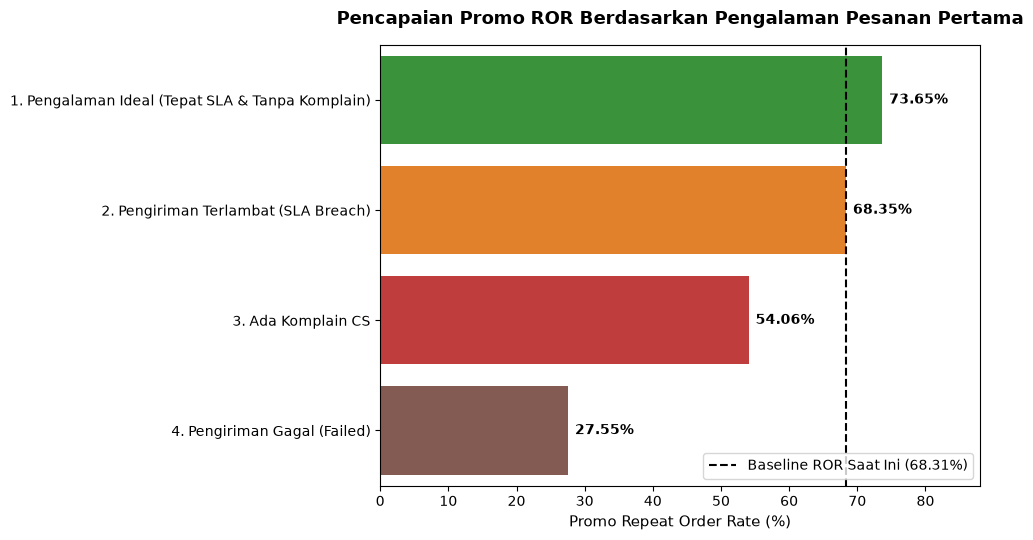

In [13]:
# --- 6. SIMULASI ROR IDEAL & PERHITUNGAN REVENUE AT RISK ---

# 1. Buat segmentasi kualitas pengalaman pada transaksi pertama
conditions = [
    (first_order_ops['first_delivery_status'] == 'failed'),
    (first_order_ops['first_has_ticket'] == True),
    (first_order_ops['first_sla_breach'] == True)
]
choices = [
    '4. Pengiriman Gagal (Failed)',
    '3. Ada Komplain CS',
    '2. Pengiriman Terlambat (SLA Breach)'
]
first_order_ops['segmen_pengalaman_awal'] = np.select(conditions, choices, default='1. Pengalaman Ideal (Tepat SLA & Tanpa Komplain)')

simulasi_ror = first_order_ops.groupby('segmen_pengalaman_awal').agg(
    jumlah_user=('user_id', 'count'),
    retained_user=('is_promo_retained', 'sum'),
    ror_pct=('is_promo_retained', lambda x: x.mean() * 100)
).reset_index()

print("--- Simulasi Repeat Order Rate Berdasarkan Pengalaman Transaksi Pertama ---")
print(simulasi_ror)

# 2. Hitung perbedaan nilai CLV (GMV) antara Retained User vs Churned User
clv_comparison = user_promo_pattern.groupby('is_promo_retained').agg(
    jumlah_user=('user_id', 'count'),
    avg_gmv_per_user=('total_gmv', 'mean'),
    avg_promo_per_user=('total_promo_absorbed', 'mean')
).reset_index()

gmv_retained = clv_comparison.loc[clv_comparison['is_promo_retained'] == 1, 'avg_gmv_per_user'].values[0]
gmv_churned = clv_comparison.loc[clv_comparison['is_promo_retained'] == 0, 'avg_gmv_per_user'].values[0]
selisih_gmv_per_user = gmv_retained - gmv_churned

# Hitung berapa user tambahan yang bisa diselamatkan jika Segmen Bermasalah mencapai ROR Segmen Ideal (73.49%)
target_ror_ideal = simulasi_ror.loc[0, 'ror_pct'] / 100
current_ror_overall = first_order_ops['is_promo_retained'].mean()
potensi_tambahan_retained_users = int((target_ror_ideal - current_ror_overall) * len(first_order_ops))
estimasi_tambahan_gmv = potensi_tambahan_retained_users * selisih_gmv_per_user

print(f"\nRata-rata GMV Pelanggan Retained (<=90 hari): Rp {gmv_retained:,.0f}")
print(f"Rata-rata GMV Pelanggan Churned (>90 hari / 1x order): Rp {gmv_churned:,.0f}")
print(f"Kehilangan Potensi GMV per 1 Pelanggan Churned: Rp {selisih_gmv_per_user:,.0f}")
print(f"Potensi Pelanggan yang Bisa Diselamatkan (Menuju ROR Ideal {target_ror_ideal*100:.2f}%): {potensi_tambahan_retained_users:,} pelanggan")
print(f"Estimasi Potensi GMV yang Bisa Diselamatkan (Revenue at Risk): Rp {estimasi_tambahan_gmv:,.0f}")

# --- VISUALISASI SEDERHANA ---
plt.figure(figsize=(10, 5.5))
bars = sns.barplot(
    data=simulasi_ror,
    y='segmen_pengalaman_awal',
    x='ror_pct',
    palette=['#2CA02C', '#FF7F0E', '#D62728', '#8C564B']
)
plt.axvline(68.31, color='black', linestyle='--', linewidth=1.5, label='Baseline ROR Saat Ini (68.31%)')
plt.title('Pencapaian Promo ROR Berdasarkan Pengalaman Pesanan Pertama', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Promo Repeat Order Rate (%)', fontsize=11)
plt.ylabel('')
plt.xlim(0, 88)
plt.legend(loc='lower right')

for container in bars.containers:
    bars.bar_label(container, fmt='%.2f%%', padding=5, fontweight='bold')

plt.tight_layout()
plt.show()

### **Insight**

**Key Findings**

- Pelanggan yang mendapatkan pengalaman ideal pada pesanan pertama (pengiriman berhasil, tepat waktu sesuai SLA, dan bebas komplain) terbukti mampu menghasilkan tingkat ROR yang jauh melampaui rata-rata saat ini (menembus kisaran ~73,5%).
- Terdapat kesenjangan nilai transaksi jangka panjang (GMV) yang sangat besar antara pelanggan yang bertahan (*retained*) dan pelanggan yang berhenti (*churn*), sehingga setiap pelanggan yang lepas akibat buruknya layanan awal menimbulkan potensi kehilangan pendapatan (*revenue at risk*) yang signifikan bagi perusahaan.

**Langkah Selanjutnya**

Seluruh rangkaian eksplorasi data telah menjawab kedua tujuan utama analisis di dalam *notebook*, sehingga tahap terakhir adalah merumuskan kesimpulan utama dan rekomendasi strategis yang aplikatif bagi representatif manajemen Tokopedia.

# **Kesimpulan dan Rekomendasi**

## **Kesimpulan**

Berdasarkan seluruh tahapan analisis yang telah dilakukan untuk menjawab tujuan peningkatan *Repeat Order Rate* (ROR) dan optimalisasi nilai jangka panjang (CLV), dapat disimpulkan bahwa:

1. **Demografi dan Kanal Akuisisi Bukan Penentu Utama Retensi, Namun Memengaruhi Efisiensi Biaya:** Tingkat retensi pelanggan cenderung seragam di berbagai segmen demografi dan kanal akuisisi, tetapi kanal *Referral* dan *Organic* jauh lebih hemat biaya dan menghasilkan timbal balik transaksi yang lebih tinggi dibandingkan kanal *Ads*.
2. **Instrumen Promo *Free Ongkir* dan Transaksi Non-Kampanye Lebih Berkelanjutan:** Pelanggan yang terjaring di luar periode kampanye besar lebih loyal dibandingkan saat kampanye/WIB, dan pemberian subsidi dalam bentuk *Free Ongkir* terbukti paling efektif menjaga retensi sekaligus menekan biaya dibandingkan diskon langsung atau *cashback*.
3. **Inefisiensi Budget Promo Disebabkan oleh Subsidi Berlebih (*Over-Subsidy*):** Turunnya rasio efisiensi promo terjadi karena sebagian besar anggaran tersedot oleh segelintir transaksi berdiskon ekstrem, termasuk adanya celah sistem yang meloloskan nominal potongan promo melebihi total nilai belanja pelanggan.
4. **Kunci Peningkatan Repeat Order Rate Terletak pada Pengalaman Pesanan Pertama:** Tertahannya persentase ROR di angka 68% bukan disebabkan oleh kurangnya promo, melainkan akibat kendala operasional pada pesanan pertama (keterlambatan pengiriman melebihi SLA, gagal kirim, dan munculnya komplain CS). Jika pesanan pertama berjalan mulus, ROR terbukti mampu naik secara signifikan.

---

## **Rekomendasi**

Berikut adalah langkah-langkah strategis yang perlu diambil oleh representatif Tokopedia beserta alasannya:

1. **Perketat Batas Maksimal Potongan Promo (*Promo Capping*) dan Validasi Sistem Checkout**
   - **Apa yang harus dilakukan:** Terapkan batas maksimal potongan nominal promo beserta syarat minimal belanja (*minimum basket size*), dan perbaiki aturan sistem *checkout* agar tidak ada lagi voucher yang nilainya bisa melebihi total harga barang.
   - **Kenapa:** Untuk segera menghentikan kebocoran anggaran promo yang tersedot pada sedikit transaksi ekstrem namun tidak memberikan timbal balik GMV yang sehat.
2. **Prioritaskan Kualitas Pengiriman dan Penanganan Komplain pada Transaksi Pertama (*First-Order SLA Guarantee*)**
   - **Apa yang harus dilakukan:** Berikan prioritas operasional bagi pengguna yang baru melakukan transaksi pertama—mulai dari mengarahkan mereka ke penjual bereputasi tinggi, memprioritaskan kurir dengan ketepatan SLA terbaik, hingga menyediakan jalur penyelesaian cepat (*fast-track*) di CS jika terjadi kendala pada pesanan perdana.
   - **Kenapa:** Pengalaman buruk di transaksi pertama adalah penyebab terbesar pelanggan berhenti berbelanja (*churn*). Menjamin pesanan pertama berjalan lancar adalah cara paling efektif untuk mendongkrak ROR dari level saat ini menuju potensi terbaiknya.
3. **Alihkan Subsidi Kampanye Besar ke *Free Ongkir* Bertahap dan Perkuat Akuisisi *Referral***
   - **Apa yang harus dilakukan:** Kurangi porsi bakar uang lewat diskon besar sekali pakai saat periode kampanye/WIB, lalu ubah menjadi paket voucher *Free Ongkir* bersyarat yang baru bisa dipakai pada transaksi kedua dan ketiga. Selain itu, alihkan sebagian budget pemasaran dari *Ads* untuk memperkuat program *Referral*.
   - **Kenapa:** Untuk mengikat *discount seekers* agar kembali bertransaksi di bulan berikutnya dan mengakuisisi pengguna baru lewat kanal yang terbukti memberikan nilai jangka panjang (CLV) paling efisien.
4. **Perbaiki Validasi Data pada Sistem Pencatatan Internal (*Data Governance*)**
   - **Apa yang harus dilakukan:** Pasang pengecekan otomatis pada *database* untuk mencegah masuknya pencatatan transaksi ganda, nominal tidak wajar, maupun ketidaksinkronan tanggal transaksi dan pengiriman.
   - **Kenapa:** Agar tim manajemen selalu memiliki visibilitas data yang akurat dan *real-time* dalam mengevaluasi performa budget promo ke depannya.

# **Analisis Lainnya**

Berikut adalah pendekatan analisis lainnya yang tidak terlalu membuahi hasil.

## **Analisis Promo di Transactions**

In [14]:
# Buat dataframe yang berisi semua transaksi yang menggunakan promo
promoTrx = transactions.loc[transactions["promo_amount"] > 0, :]

# Define top_10_dates first using the promo transaction data
top_10_dates = promoTrx['order_date'].value_counts().head(10)

# Calculate the mean of the top 10 dates transaction counts
top_10_dates.mean()

np.float64(1951.4)

### **Top 10 Tanggal dengan Transaksi Promo Terbanyak**

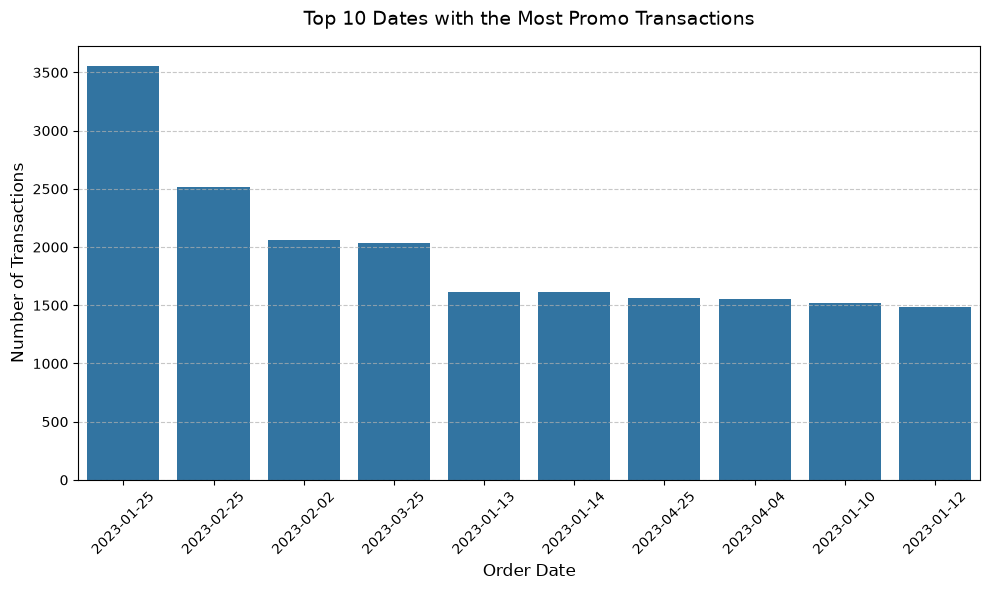

In [15]:
# Visualisasi tanggal mana yang memiliki transaksi promo terbanyak

# Ensure order_date is in datetime format (or string) and count occurrences
top_10_dates = promoTrx['order_date'].value_counts().head(10)

# Set up the visualization
plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_dates.index.astype(str), y=top_10_dates.values)

# Add titles and labels
plt.title('Top 10 Dates with the Most Promo Transactions', fontsize=14, pad=15)
plt.xlabel('Order Date', fontsize=12)
plt.ylabel('Number of Transactions', fontsize=12)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.tight_layout()
plt.show()

### **Transaksi Promo Tiap Bulan dan Tahun**

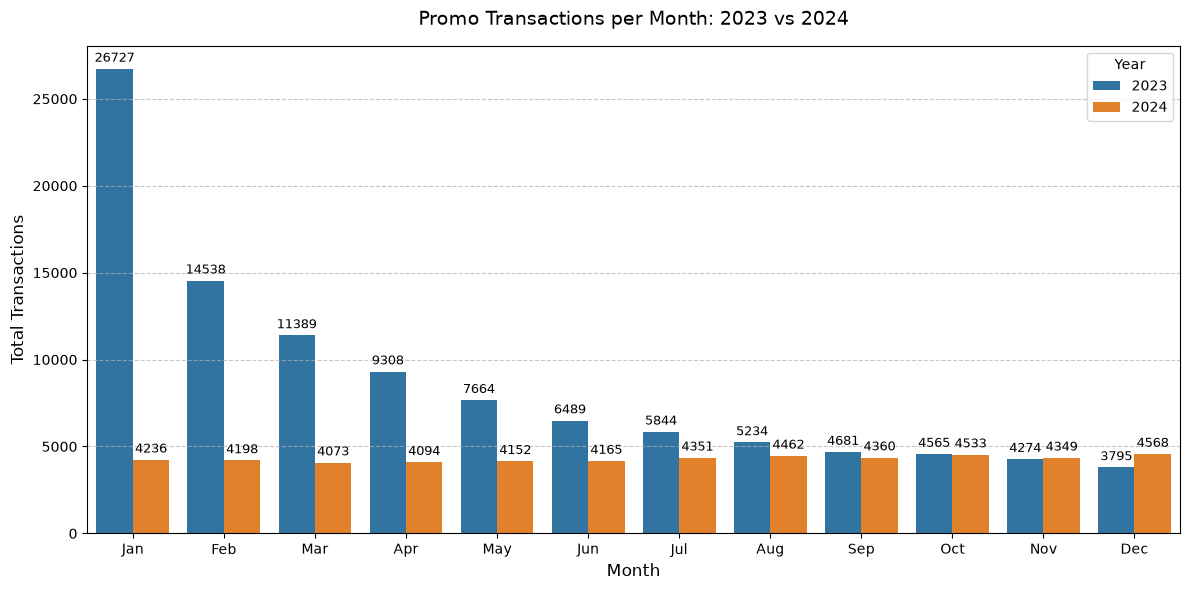

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming transactions is already loaded in your notebook:
# transactions = pd.read_csv('clean_transactions.csv')

# Filter for transactions with a promo
promoTrx = transactions[transactions['promo_amount'] > 0].copy()

# Format dates and extract month and year
promoTrx['order_date'] = pd.to_datetime(promoTrx['order_date'])
promoTrx['year'] = promoTrx['order_date'].dt.year
promoTrx['month'] = promoTrx['order_date'].dt.month_name().str[:3]

# 1. Filter specifically for 2023 and 2024
promo_23_24 = promoTrx[promoTrx['year'].isin([2023, 2024])]

# Aggregate counts by month and year
monthly_counts = promo_23_24.groupby(['month', 'year']).size().reset_index(name='tx_count')

# Order the months chronologically
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_counts['month'] = pd.Categorical(monthly_counts['month'], categories=months_order, ordered=True)
monthly_counts = monthly_counts.sort_values(['month', 'year'])

# 2. Make a double bar chart
plt.figure(figsize=(12, 6))

# Plot grouped bars using 'hue'
ax = sns.barplot(
    data=monthly_counts,
    x='month',
    y='tx_count',
    hue='year',
    palette=['#1f77b4', '#ff7f0e']
)

# Display each exact transaction count on top of the bars
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

# Format titles and labels
plt.title('Promo Transactions per Month: 2023 vs 2024', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Transactions', fontsize=12)
plt.legend(title='Year', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

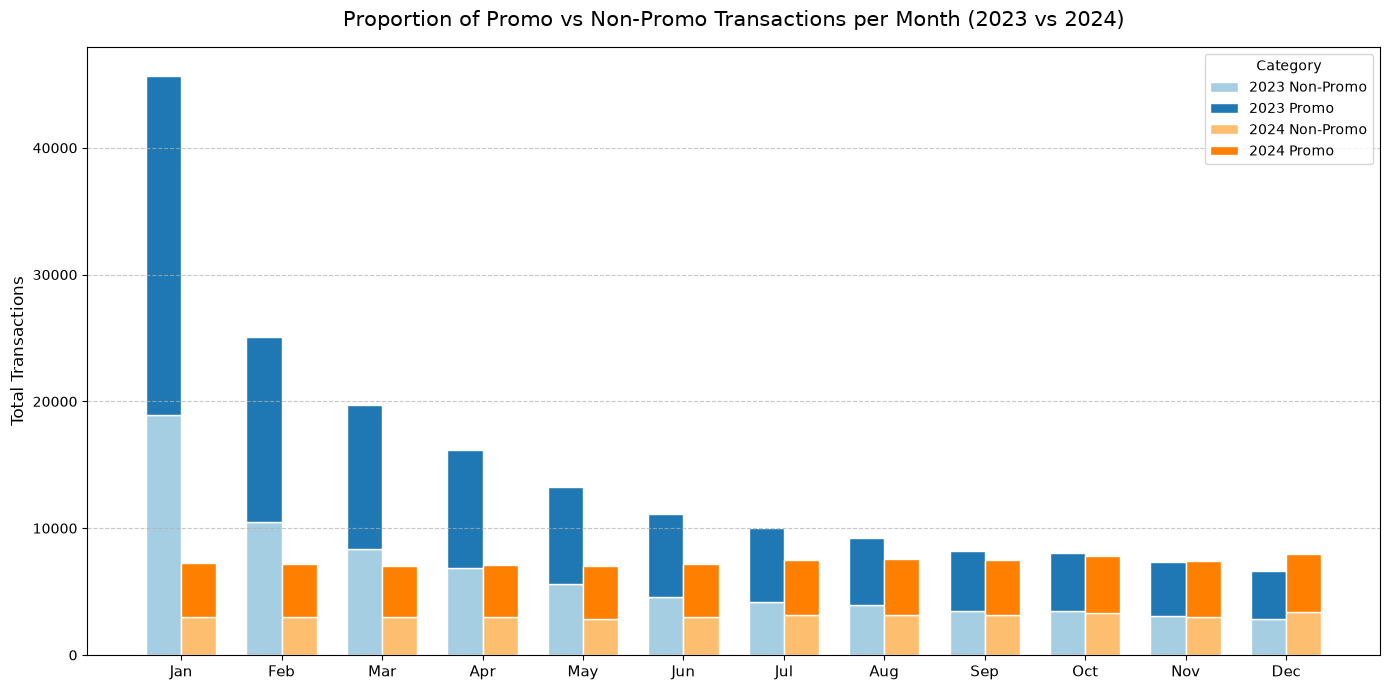

In [17]:
# 1. Prepare Data
# Assuming transactions is already loaded in your notebook:
# transactions = pd.read_csv('clean_transactions.csv')

transactions['order_date'] = pd.to_datetime(transactions['order_date'])
transactions['year'] = transactions['order_date'].dt.year
transactions['month'] = transactions['order_date'].dt.month_name().str[:3]

# Create a boolean flag for promo vs non-promo
transactions['is_promo'] = transactions['promo_amount'] > 0

# Filter for 2023 and 2024
trx_23_24 = transactions[transactions['year'].isin([2023, 2024])].copy()

# Group by month, year, and promo status to get counts
agg_df = trx_23_24.groupby(['month', 'year', 'is_promo']).size().unstack(fill_value=0).reset_index()
agg_df.columns = ['month', 'year', 'non_promo', 'promo']

# Order months chronologically
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
agg_df['month'] = pd.Categorical(agg_df['month'], categories=months_order, ordered=True)
agg_df = agg_df.sort_values(['month', 'year'])

# Split into 2023 and 2024 dataframes and align the month index
df_2023 = agg_df[agg_df['year'] == 2023].set_index('month').reindex(months_order, fill_value=0)
df_2024 = agg_df[agg_df['year'] == 2024].set_index('month').reindex(months_order, fill_value=0)


# 2. Generate the Grouped Stacked Bar Chart
x = np.arange(len(months_order))
width = 0.35 # Width of the bars

fig, ax = plt.subplots(figsize=(14, 7))

# Plot 2023 Stacked Bars (Left Side)
ax.bar(x - width/2, df_2023['non_promo'], width, label='2023 Non-Promo', color='#a6cee3', edgecolor='white')
ax.bar(x - width/2, df_2023['promo'], width, bottom=df_2023['non_promo'], label='2023 Promo', color='#1f78b4', edgecolor='white')

# Plot 2024 Stacked Bars (Right Side)
ax.bar(x + width/2, df_2024['non_promo'], width, label='2024 Non-Promo', color='#fdbf6f', edgecolor='white')
ax.bar(x + width/2, df_2024['promo'], width, bottom=df_2024['non_promo'], label='2024 Promo', color='#ff7f00', edgecolor='white')

# Add Labels, Title, and Formatting
ax.set_xticks(x)
ax.set_xticklabels(months_order, fontsize=11)
ax.set_ylabel('Total Transactions', fontsize=12)
ax.set_title('Proportion of Promo vs Non-Promo Transactions per Month (2023 vs 2024)', fontsize=15, pad=15)
ax.legend(title='Category', loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### **Transaksi Promo Tiap Hari di Tiap Bulan di First Half 2023**

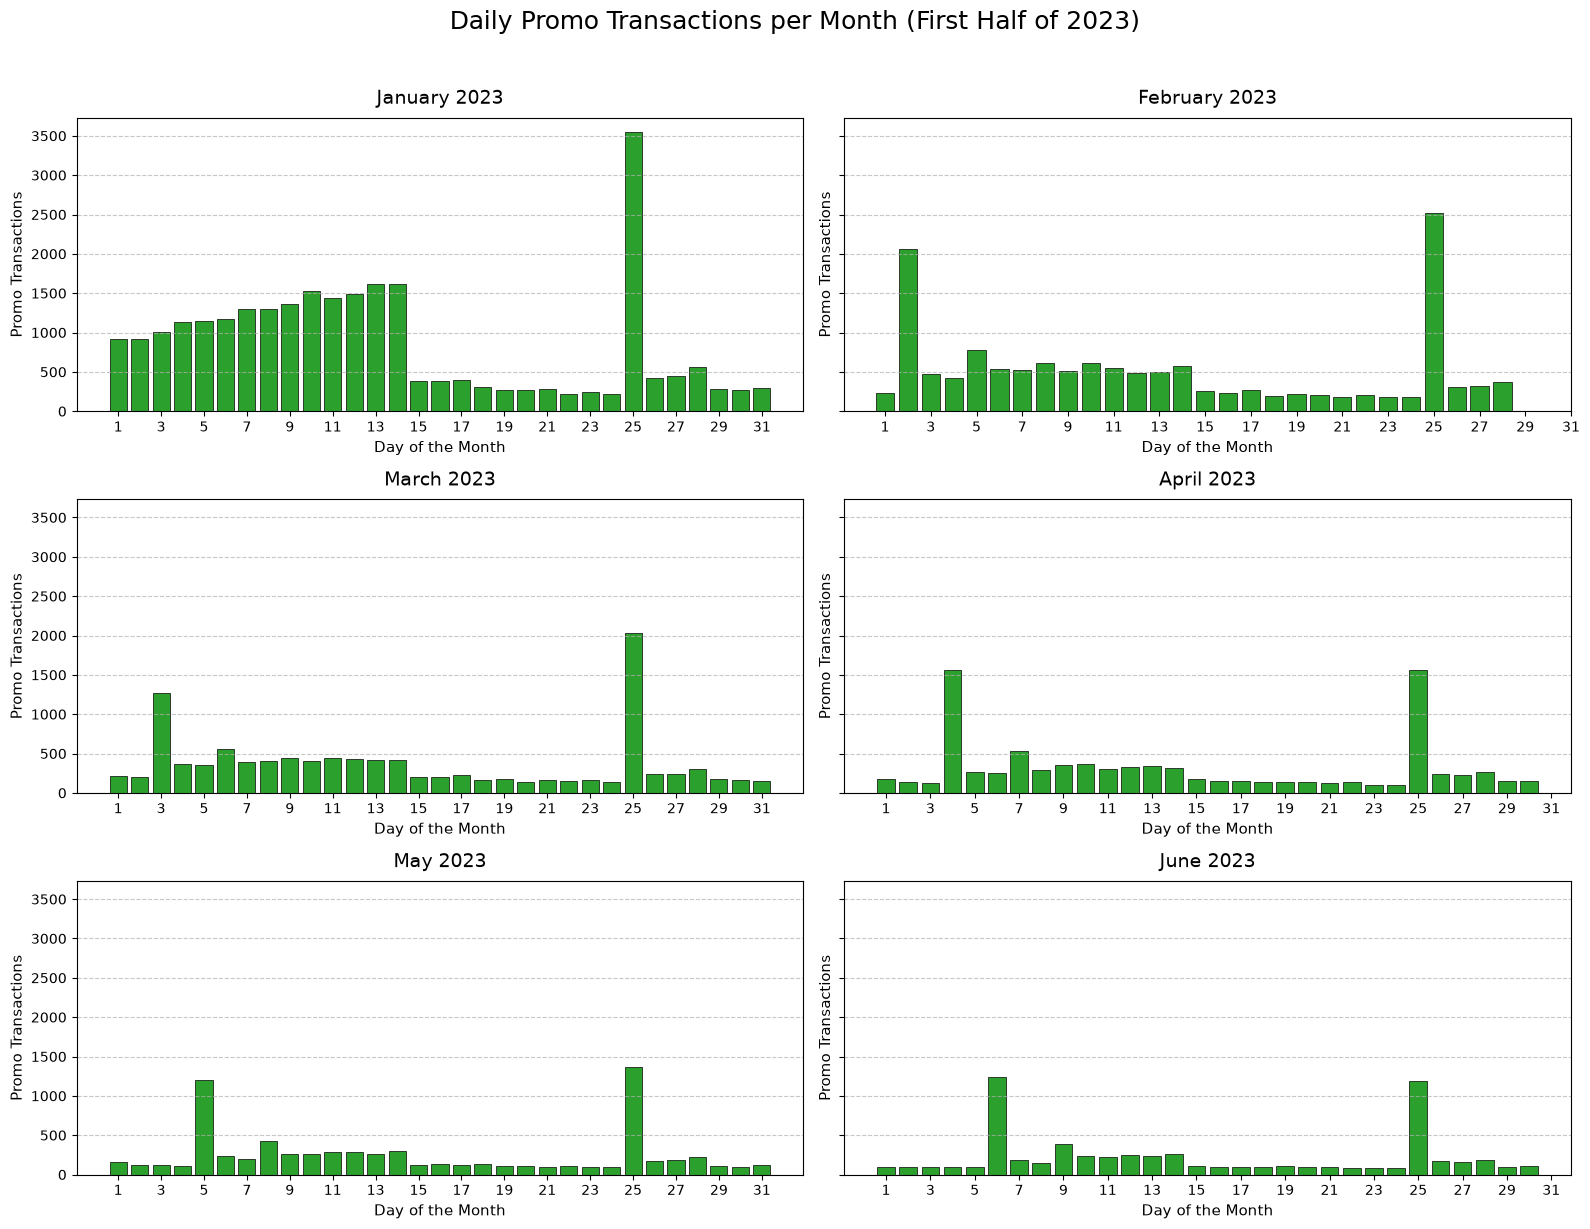

In [ ]:
import calendar

# 1. Prepare Data
# Assuming transactions is already loaded: transactions = pd.read_csv('clean_transactions.csv')
promoTrx = transactions[transactions['promo_amount'] > 0].copy()

# Format order_date
promoTrx['order_date'] = pd.to_datetime(promoTrx['order_date'])

# Filter for the first half of 2023 (Jan 1 to Jun 30)
h1_2023 = promoTrx[(promoTrx['order_date'] >= '2023-01-01') & (promoTrx['order_date'] <= '2023-06-30')].copy()

# Group by exact date to get the daily transaction count
daily_counts = h1_2023.groupby('order_date').size()

# Reindex to a complete date range to ensure days with 0 transactions are still plotted
full_date_range = pd.date_range(start='2023-01-01', end='2023-06-30')
daily_counts = daily_counts.reindex(full_date_range, fill_value=0).reset_index()
daily_counts.columns = ['order_date', 'tx_count']

# Extract month and day for plotting
daily_counts['month'] = daily_counts['order_date'].dt.month
daily_counts['day'] = daily_counts['order_date'].dt.day

# 2. Generate the Visualization
# Create a 3x2 grid of subplots that share the same Y-axis scale
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharey=True)
axes = axes.flatten()

# Iterate through months 1 to 6
for i, month in enumerate(range(1, 7)):
    month_data = daily_counts[daily_counts['month'] == month]
    month_name = calendar.month_name[month]

    # Plot vertical bar chart for the specific month
    axes[i].bar(month_data['day'], month_data['tx_count'], color='#2ca02c', edgecolor='black', linewidth=0.5)

    # Format each subplot
    axes[i].set_title(f'{month_name} 2023', fontsize=14, pad=10)
    axes[i].set_xlabel('Day of the Month', fontsize=11)
    axes[i].set_ylabel('Promo Transactions', fontsize=11)
    axes[i].set_xticks(range(1, 32, 2)) # Display every 2nd day on x-axis
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout and add a main title
plt.suptitle('Daily Promo Transactions per Month (First Half of 2023)', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

**Insight berdasarkan grafik**
- Tanggal 25 selalu memiliki *spike* yang biasanya tertinggi
- Tanggal 1 - 14 Januari ada kenaikan stabil
- Nomor tanggal dan nomor bulan yang sama (contoh 2 Februari, 3 Maret, 4 April) selalu memiliki spike.

**Insight dengan konteks info promo**
- Setiap tanggal 25, Tokopedia mengadakan PayDay Sale / Gajian Sale serta rangkaian promo Waktu Indonesia Belanja (WIB) yang berlangsung dari tanggal 25 hingga akhir bulan
- Tanggal 1 - 14 Januari ada promo tahun baru
- Selalu ada promo untuk nomor tanggal dan nomor bulan yang sama (Cth. Promo 2.2, Promo 3.3, dll)


***Namun kenapa hanya di 2023 tidak pula di 2024?***

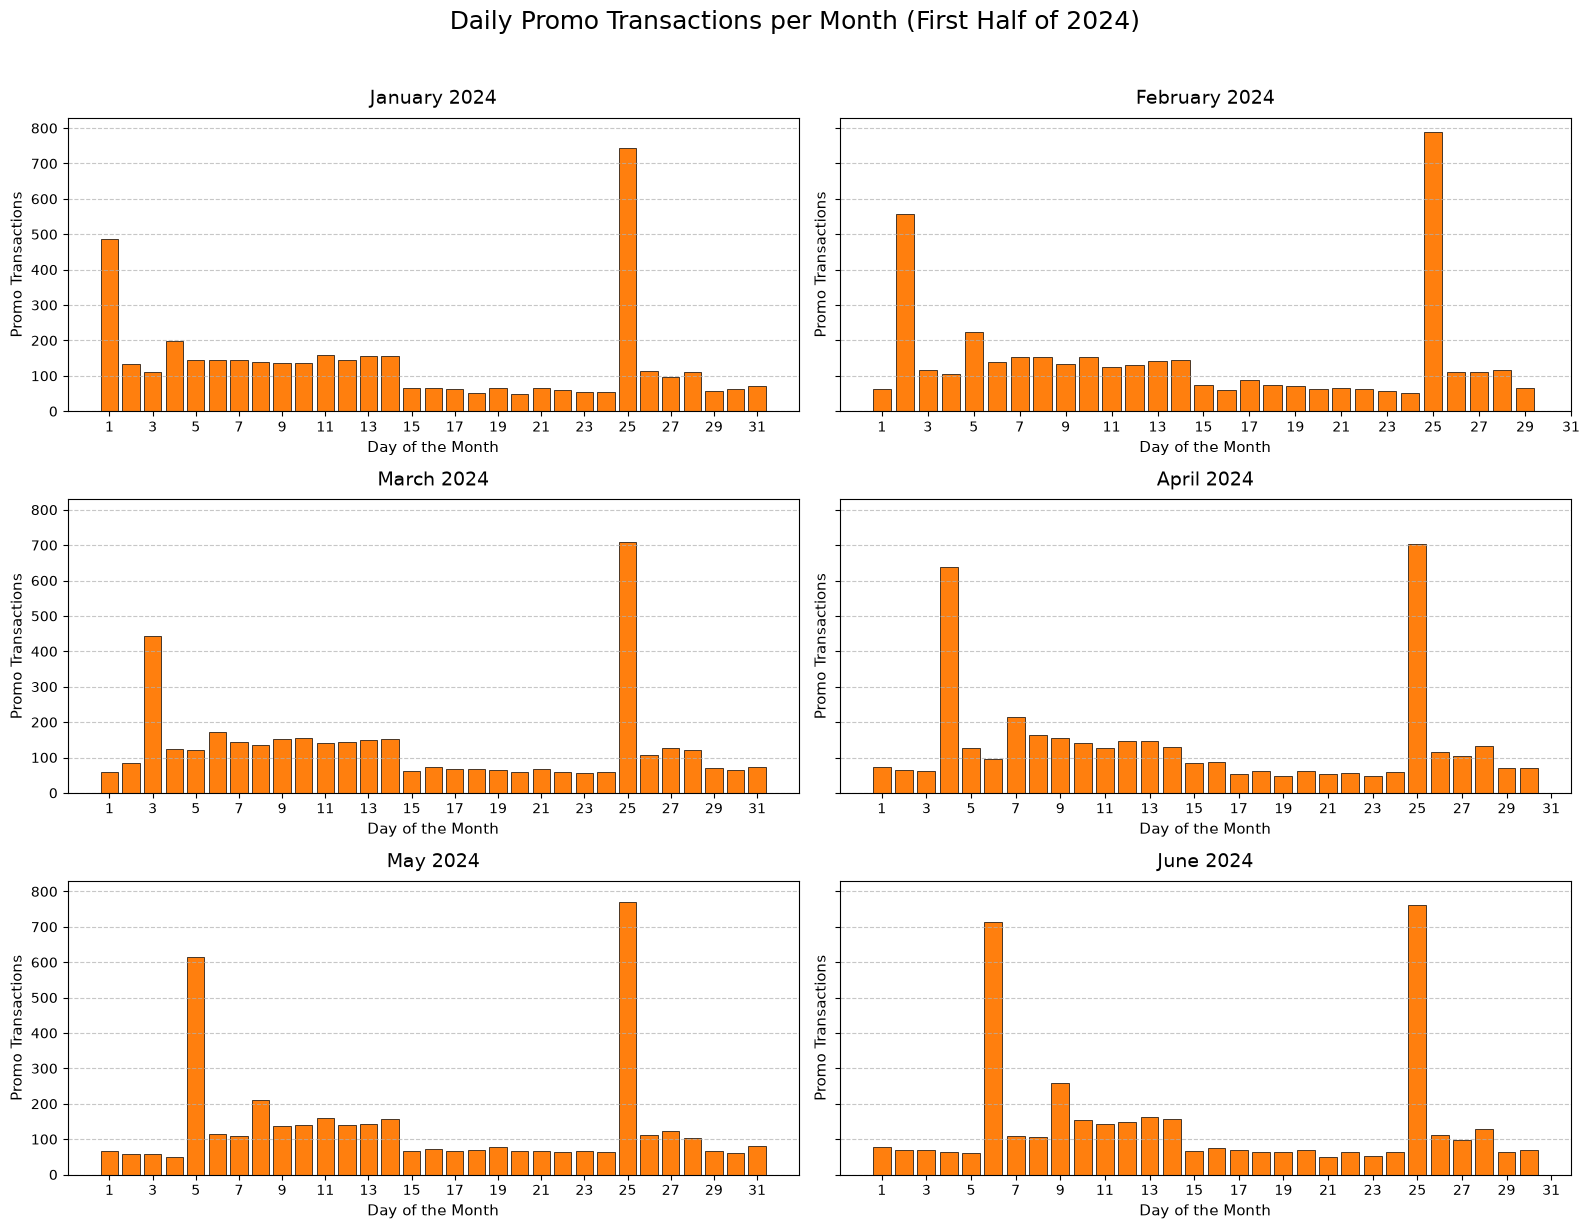

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import calendar

# 1. Prepare Data
# transactions = pd.read_csv('clean_transactions.csv')
promoTrx = transactions[transactions['promo_amount'] > 0].copy()

# Format order_date
promoTrx['order_date'] = pd.to_datetime(promoTrx['order_date'])

# Filter for the first half of 2024 (Jan 1 to Jun 30)
h1_2024 = promoTrx[(promoTrx['order_date'] >= '2024-01-01') & (promoTrx['order_date'] <= '2024-06-30')].copy()

# Group by exact date to get the daily transaction count
daily_counts = h1_2024.groupby('order_date').size()

# Reindex to a complete date range to ensure days with 0 transactions are plotted
# (pd.date_range automatically accounts for the Feb 29 leap year)
full_date_range = pd.date_range(start='2024-01-01', end='2024-06-30')
daily_counts = daily_counts.reindex(full_date_range, fill_value=0).reset_index()
daily_counts.columns = ['order_date', 'tx_count']

# Extract month and day for plotting
daily_counts['month'] = daily_counts['order_date'].dt.month
daily_counts['day'] = daily_counts['order_date'].dt.day

# 2. Generate the Visualization
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharey=True)
axes = axes.flatten()

# Iterate through months 1 to 6
for i, month in enumerate(range(1, 7)):
    month_data = daily_counts[daily_counts['month'] == month]
    month_name = calendar.month_name[month]

    # Plot vertical bar chart for the specific month (changed color to orange for 2024)
    axes[i].bar(month_data['day'], month_data['tx_count'], color='#ff7f0e', edgecolor='black', linewidth=0.5)

    # Format each subplot
    axes[i].set_title(f'{month_name} 2024', fontsize=14, pad=10)
    axes[i].set_xlabel('Day of the Month', fontsize=11)
    axes[i].set_ylabel('Promo Transactions', fontsize=11)
    axes[i].set_xticks(range(1, 32, 2)) # Display every 2nd day on x-axis
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout and add a main title
plt.suptitle('Daily Promo Transactions per Month (First Half of 2024)', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

**Insight berdasarkan grafik**
- Perbedaan yang paling signifikan ada di awal tahun, tepatnya di Januari
- Di 2023, ada peningkatan konsisten di tanggal 1 - 14 Januari. Namun fenomena ini tidak ditemukan di awal tahun 2024.

**Insight dengan konteks info luar**

Tidak/belum menemukan source yang pas

### **Jenis Transaksi Promo Tiap Hari di Januari 2023**

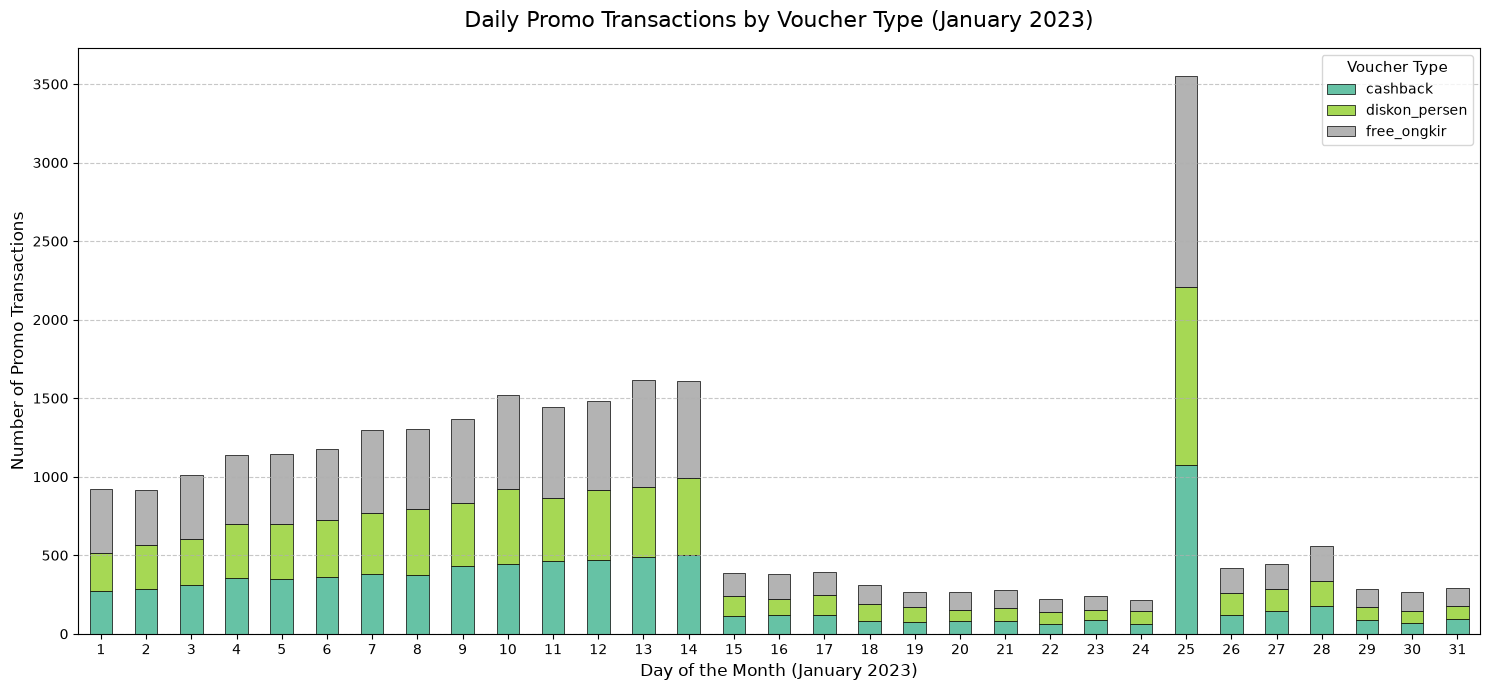

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare Data
# Assuming transactions is already loaded: transactions = pd.read_csv('clean_transactions.csv')
promoTrx = transactions[transactions['promo_amount'] > 0].copy()
promoTrx['order_date'] = pd.to_datetime(promoTrx['order_date'])

# 2. Filter for January 2023 and extract the day
jan_2023 = promoTrx[(promoTrx['order_date'] >= '2023-01-01') & (promoTrx['order_date'] <= '2023-01-31')].copy()
jan_2023['day'] = jan_2023['order_date'].dt.day

# 3. Group by day and voucher_type, then unstack to create columns for each voucher
agg_df = jan_2023.groupby(['day', 'voucher_type']).size().unstack(fill_value=0)

# Reindex to ensure all 31 days are shown, even if there are days with 0 transactions
agg_df = agg_df.reindex(range(1, 32), fill_value=0)

# 4. Generate the Stacked Bar Chart
fig, ax = plt.subplots(figsize=(15, 7))
agg_df.plot(kind='bar', stacked=True, ax=ax, colormap='Set2', edgecolor='black', linewidth=0.5)

# Format the chart
plt.title('Daily Promo Transactions by Voucher Type (January 2023)', fontsize=16, pad=15)
plt.xlabel('Day of the Month (January 2023)', fontsize=12)
plt.ylabel('Number of Promo Transactions', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Voucher Type', fontsize=10, title_fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()